# Geometrie und Trigonometrie

## 07 - Trigonometrie 1: Rechtwinkliges Dreieck

Bisher hatten wir zwei getrenne Welten:
1. **Winkel** (gemessen in Grad, z.B. $30°$).
2. **Seitenlängen** (gemessen in Metern, cm, etc.).

Der Satz des Pythagoras ($a^2 + b^2 = c^2$) hilft uns nur, wenn wir zwei Seiten kennen und die dritte suchen. Er sagt uns nicht über die Winkel.
Was aber, wenn wir wissen wollen, wie hoch eine Rampe wird, wenn sie 10 Meter lang ist und einen Steigungswinkel von $15°$ hat?
Hier brauchen wir die **Trigonometrie**.

Mit der Trigonometrie bauen wir eine Brücke zwischen **Winekln** und **Längen**.

**Lernziele:**
- Du verstehst, warum Seitenverhältnisse in ähnlichen Dreiecken konstant sind.
- Du lernst die Definitionen von **Sinus**, **Cosinus** und **Tangens**.
- Du verstehst den Tangens als **Steigung**.
- Du kanns wichtige Werte (für $30°, 45°, 60°$) geometrisch herleiten, ohne Taschenrechner.
- Du kannst Python nutzen, um diese Zusammenhänge zu visalisieren.


### 1. Das Fundament: Ähnlichkeit

Warum funktionieren Sinus und Cosinus überhaupt?

Nehmen wir ein kleines rechtwinkliges Dreieck mit einem Winkel $\alpha = 30°$.
Dann nehmen wir ein riesiges rechtwinkliges Dreieck, das ebenfalls einen Winkel $\alpha = 30°$ hat.

Da beide Dreiecke zwei gleiche Winkel haben ($30°$ und $90°$), ist auch der dritte Winkel gleich ($60°$). Nach dem Ähnlichkeitssatz (WW) sind die Dreiecke **ähnlich**.

**Die Konsequenz:**
Das Verhältnis der Seitenlängen zueinander ist in beiden Dreiecken **identisch**.
Wenn im kleinen Dreieck die Höhe genau halb so lang ist wie die schräge Seite, dann ist das im riesigen Dreieck auch so.

Diese konstanten Verhältnisse haben Namen bekommen: Sinus, Cosinus und Tangens.

### 2. Die Definitionen

Um die Verhältnisse zu bilden, müssen wir die Seiten relativ zum betrachteten Winkel $\alpha$ benennen:

1.  **Hypotenuse ($H$):** Immer die längste Seite, gegenüber vom rechten Winkel.
2.  **Gegenkathete ($GK$):** Die Seite, die dem Winkel $\alpha$ **gegenüber** liegt.
3.  **Ankathete ($AK$):** Die Seite, die **am** Winkel $\alpha$ anliegt (und nicht die Hypotenuse ist).

Die drei Grundfunktionen sind definiert als:

$$\sin(\alpha) = \frac{\text{Gegenkathete}}{\text{Hypotenuse}} = \frac{GK}{H}$$

$$\cos(\alpha) = \frac{\text{Ankathete}}{\text{Hypotenuse}} = \frac{AK}{H}$$

$$\tan(\alpha) = \frac{\text{Gegenkathete}}{\text{Ankathete}} = \frac{GK}{AK}$$


In [1]:
# Settings für Intro Grafik

Trig_Intro_Grafik = {
    "angle_deg": 45,
    "hypotenuse": 10,
    "figsize": (8, 6),
    "color_gk": "red",
    "color_ak": "blue",
    "color_hyp": "black"
}

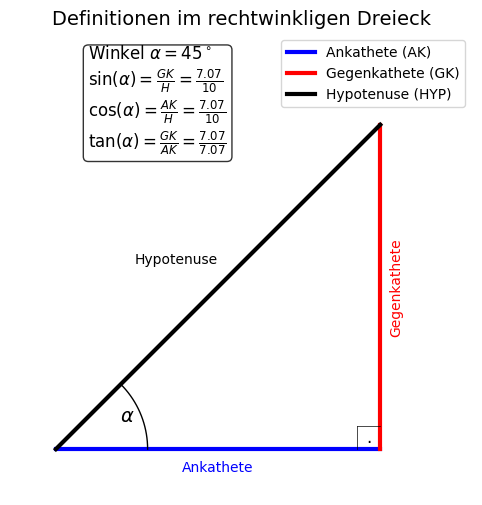

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def plot_trig_definitions(ax, cfg):
    alpha = np.radians(cfg["angle_deg"])
    h = cfg["hypotenuse"]

    # Katheten berechnen
    ak = h * np.cos(alpha)
    gk = h * np.sin(alpha)

    # Dreieck zeichnen
    # Punkte: A(0,0), B(ak,0), C(ak,gk)
    ax.plot([0, ak], [0, 0], color=cfg["color_ak"], lw=3, label="Ankathete (AK)")
    ax.plot([ak, ak], [0, gk], color=cfg["color_gk"], lw=3, label="Gegenkathete (GK)")
    ax.plot([0, ak], [0, gk], color=cfg["color_hyp"], lw=3, label="Hypotenuse (HYP)")

    # Rechter Winkel
    box_s = h * 0.05
    ax.plot([ak, ak-box_s], [box_s, box_s], 'k-', lw=0.5)
    ax.plot([ak-box_s, ak-box_s], [0, box_s], 'k-', lw=0.5)
    ax.text(ak - box_s/2, box_s/2, ".", ha="center", va="center", fontsize=12)

    # Winkel Alpha Bogen
    arc_r = h * 0.2
    arc_x = np.linspace(0, alpha, 20)
    ax.plot(arc_r * np.cos(arc_x), arc_r * np.sin(arc_x), 'k-', lw=1)
    ax.text(arc_r * 0.7, arc_r * 0.3, r"$\alpha$", fontsize=14)

    """
    ValueError: 
Winkel $\alpha = 35^\circ$$\sin(\\alpha) = \\frac{GK}{H} = \\frac{5.74}{10} = {gk/h:.2f}$
                          ^
ParseException: Expected end of text, found '$'  (at char 26), (line:1, col:27)
    """

    # Formeln als Text
    info_text = (
        f"Winkel $\\alpha = {cfg['angle_deg']}^\\circ$\n"
        r"$\sin(\alpha) = \frac{GK}{H} = \frac{" + f"{gk:.2f}" + r"}{" + f"{h}" + r"}$" + "\n"
        r"$\cos(\alpha) = \frac{AK}{H} = \frac{" + f"{ak:.2f}" + r"}{" + f"{h}" + r"}$" + "\n"
        r"$\tan(\alpha) = \frac{GK}{AK} = \frac{" + f"{gk:.2f}" + r"}{" + f"{ak:.2f}" + r"}$"
    )
    ax.text(ak * 0.1, gk - 0.5, info_text, fontsize=12, bbox=dict(boxstyle="round", fc="white", alpha=0.8))

    # Labels an den Seiten
    ax.text(ak/2, -h*0.05, "Ankathete", ha='center', color=cfg["color_ak"])
    ax.text(ak + h*0.02, gk/2, "Gegenkathete", va='center', rotation=90, color=cfg["color_gk"])
    ax.text(ak/2, gk/2 + h*0.05, "Hypotenuse", ha='right', color=cfg["color_hyp"])

    ax.set_xlim(-1, ak +2)
    ax.set_ylim(-1, gk +2)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title("Definitionen im rechtwinkligen Dreieck", fontsize=14)
    ax.legend(loc='upper right')

fig, ax = plt.subplots(figsize=Trig_Intro_Grafik["figsize"])
plot_trig_definitions(ax, Trig_Intro_Grafik)
plt.show()



### 3. Der Tangens als Steigung

Erinnern wir uns an die lineare Funktionen: $y = k \cdot x + d$.

Dabei war $k$ die **Steigung** (oft auch $m$ genannt).

Die Steigung war definiert als: $\frac{\Delta y}{\Delta x}$ ("Höhenunterschied durch Längenunterschied").

Schauen wir uns das Dreieck oben an:
- $\Delta y$ ist die Gegenkathete.
- $\Delta x$ ist die Ankathete.

Daraus folgt eine der wichtigsten Erkenntnisse für die technische Mathematik:
**Die Steigung einer Geraden ist der Tangens ihres Steigungswinkels.**

$$\text{Steigung } k = \tan(\alpha)$$

Beispiel: Eine Straße mit $100\%$ Steigung.
Das heißt $\Delta y = \Delta x$ (z.B. 100m hoch auf 100m Distanz).
$\tan(\alpha) = 1$. Welcher Winkel hat den Tangens 1? $\rightarrow 45°$.
Eine 100%ige Steigung entspricht also einem $45°$-Winkel, nicht $90°$!

### 4. Herleitungen

Wir können diese Verhältnisse geometrisch beweisen:

#### A. Der 45°-Fall (Halbes Quadrat)
Nimm ein Quadrat mit Seitenlänge $1$. Schneide es diagonal durch.
- Die Winkel sind $90°, 45°, 45°$.
- Die Katheten sind $a=1, b=1$
- Die Hypotenuse ist laut Pythagoras $c = \sqrt{1^2 + 1^2} = \sqrt{2}$.

Daraus folgt:
$$\sin(45°) = \frac{GK}{H} = \frac{1}{\sqrt{2}} = \frac{\sqrt{2}}{2} \approx 0.707$$
$$\tan(45°) = \frac{GK}{AK} = \frac{1}{1} = 1$$

In [272]:
Trig_45_Grafik = {
    "hypotenuse": 14,
    "figsize": (8, 6),
    "color_trig": "green",
    "color_square_fill": "orange",
    "angle_radius_factor": 0.2
}

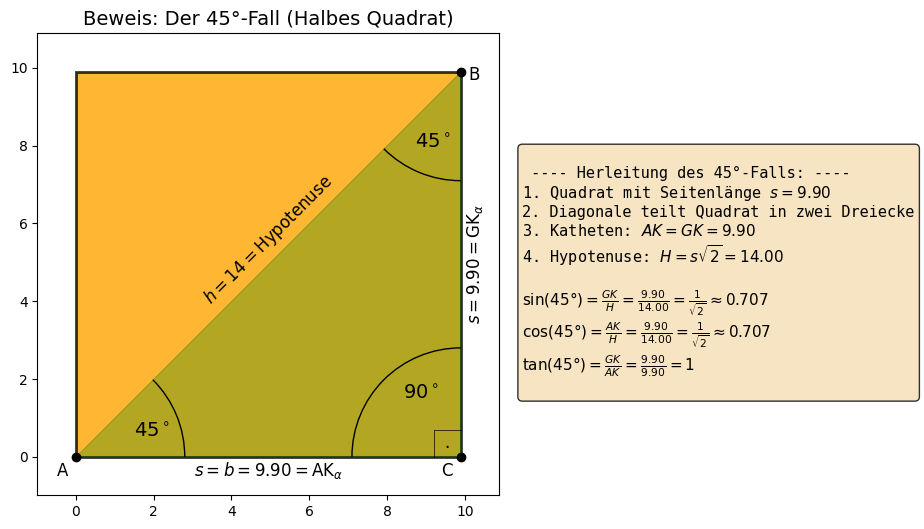

In [273]:
# Visualisierung des 45°-Falls
from matplotlib.patches import Rectangle, Polygon, Arc

# Please add a legend with a german breakdown of the proof as above to this function
def plot_split_square(ax, cfg):
    alpha = np.radians(45)
    beta = np.radians(45)
    gamma = np.radians(90)

    h = cfg["hypotenuse"]
    ak_a = h * np.cos(alpha)
    gk_a = h * np.sin(alpha)

    ak_c = gk_a
    gk_c = ak_a

    # Berechnen
    # Quadratgröße
    square_size = h / np.sqrt(2) # s = h / √a² + b² = h / √2

    scale_factor = square_size * 0.1

    # Achsen einstellen
    Grid = ((-scale_factor, square_size + scale_factor), (-scale_factor, square_size + scale_factor))
    ax.set_xlim(Grid[0][0], Grid[0][1])
    ax.set_ylim(Grid[1][0], Grid[1][1])
    
    # Quadrat zeichnen
    square = Rectangle((0, 0,), square_size, square_size, fill=True, facecolor=cfg["color_square_fill"], edgecolor='black', lw=2, alpha=0.8)
    ax.add_patch(square)

    # Quadrat teilen (ein Dreieck einzeichnen)
    triangle = Polygon([[0+0.01, 0+0.01], [ak_a-0.01, 0+0.01], [ak_a-0.01, gk_a-0.01]], closed=True, fill=True, facecolor=cfg["color_trig"], edgecolor=cfg["color_trig"], lw=0.8, alpha=0.3)
    ax.add_patch(triangle)

    # Punkte einzeichnen
    ax.plot(0, 0, 'ko')
    ax.text(-0.5 * scale_factor, -0.5 * scale_factor, "A", fontsize=12)

    ax.plot(ak_a, 0, 'ko')
    ax.text(ak_a - 0.5 * scale_factor, -0.5 * scale_factor, "C", fontsize=12)

    ax.plot(ak_a, gk_a, 'ko')
    ax.text(ak_a + 0.2 * scale_factor, gk_a - 0.2 * scale_factor, "B", fontsize=12)

    # Winkel einzeichnen
    arc_r = h * cfg["angle_radius_factor"]

    ax.add_patch(Arc((0, 0), 2*arc_r, 2*arc_r, angle=0, theta1=0, theta2=45, lw=1, color='k'))
    ax.text(0 + 1.5 * scale_factor, 0 + 0.5 * scale_factor, r"$45^\circ$", fontsize=14)

    ax.add_patch(Arc((square_size, 0), 2*arc_r, 2*arc_r, angle=0, theta1=90, theta2=180, lw=1, color='k'))
    ax.text(square_size - 1.5 * scale_factor, 0 + 1.5 * scale_factor, r"$90^\circ$", fontsize=14)

    ax.add_patch(Arc((square_size, square_size), 2*arc_r, 2*arc_r, angle=0, theta1=225, theta2=270, lw=1, color='k'))
    ax.text(square_size - 1.2 * scale_factor, square_size - 2.0 * scale_factor, r"$45^\circ$", fontsize=14)

    box_s = h * 0.05 
    ax.plot([ak_a, ak_a-box_s], [box_s, box_s], 'k-', lw=0.5)
    ax.plot([ak_a-box_s, ak_a-box_s], [0, box_s], 'k-', lw=0.5)
    ax.text(ak_a - box_s/2, box_s/2, ".", ha="center", va="center", fontsize=12)

    # Seiten beschriften
    ax.text(ak_a/2, -0.5 * scale_factor, f"$s = b = {square_size:.2f} = \\text{{AK}}_\\alpha $", ha='center', fontsize=12)
    ax.text(ak_a + 0.1 * scale_factor, gk_a/2, f"$s = {square_size:.2f} = \\text{{GK}}_\\alpha$", va='center', rotation=90, fontsize=12)
    ax.text(ak_a/2, gk_a / 2 - scale_factor, f"$h = {h} = \\text{{Hypotenuse}}$", ha='center', fontsize=12, rotation=45)

    # Legende mit Herleitung
    form_square_size = f"{square_size:.2f}"
    form_h = f"{h:.2f}"

    legend_text = (
        "\n"
        " ---- Herleitung des 45°-Falls: ---- \n"
        f"1. Quadrat mit Seitenlänge $s = {form_square_size}$\n"
        f"2. Diagonale teilt Quadrat in zwei Dreiecke\n"
        f"3. Katheten: $AK = GK = {form_square_size}$\n"
        f"4. Hypotenuse: $H = s\\sqrt{{2}} = {form_h}$\n\n"
        f"$\\sin(45°) = \\frac{{GK}}{{H}} = \\frac{{{form_square_size}}}{{{form_h}}} = \\frac{{1}}{{\\sqrt{{2}}}} \\approx 0.707$\n"
        f"$\\cos(45°) = \\frac{{AK}}{{H}} = \\frac{{{form_square_size}}}{{{form_h}}} = \\frac{{1}}{{\\sqrt{{2}}}} \\approx 0.707$\n"
        f"$\\tan(45°) = \\frac{{GK}}{{AK}} = \\frac{{{form_square_size}}}{{{form_square_size}}} = 1$"
        "\n"
    )
    ax.text(1.05, 0.75, legend_text, transform=ax.transAxes, fontsize=11, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
            family='monospace')

    ax.set_title("Beweis: Der 45°-Fall (Halbes Quadrat)", fontsize=14)
    ax.set_aspect('equal')




fig, ax = plt.subplots(figsize=Trig_45_Grafik["figsize"])
plot_split_square(ax, Trig_45_Grafik)
plt.show()


#### B. Der 30°/60°-Fall (Das halbe gleichseitige Dreieck)
Nimm ein gleichseitiges Dreieck mit Seitenlänge $2$. Alle Winkel sind $60°$.
Schneide es in der Mitte senkrecht durch (Höhe).
- Die untere Seite (Länge 2) wird halbiert $\rightarrow$ Ankathete für $60°$ ist $1$.
- Die Hypotenuse ist immer noch die Originalseite $\rightarrow 2$.
- Die Höhe (Gegenkathete für $60°$) ist laut Pythagoras: $h = \sqrt{2^2 - 1^2} = \sqrt{3}$.
- Der obere Winkel wurde halbiert $\rightarrow 30°$.

Daraus folgt für $30°$:
$$\sin(30°) = \frac{GK}{H} = \frac{1}{2} = 0.5$$
$$\cos(30°) = \frac{AK}{H} = \frac{\sqrt{3}}{2} \approx 0.866$$

In [274]:
Trig_30_60_Grafik = {
    "hypotenuse": 14,
    "figsize": (8, 6),
    "color_trig_30": "lightblue",
    "color_trig_60": "lightcoral",
    "color_triangle_fill": "lightyellow",
    "angle_radius_factor": 0.2
}

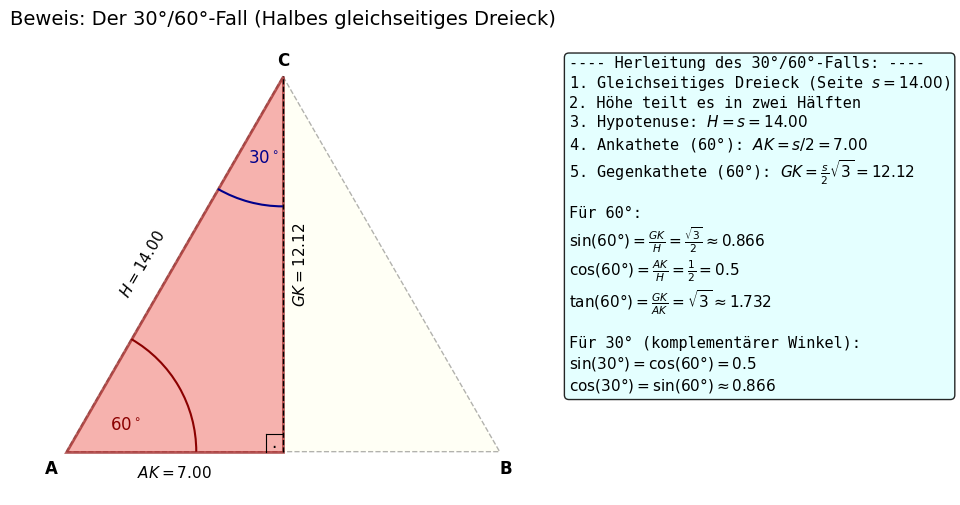

In [275]:
# Visualisierung des 30°-60°-Falls

def plot_split_equilateral_triangle(ax, cfg):
    """
    Visualisiert das halbe gleichseitige Dreieck zur Herleitung von sin/cos(30°) und sin/cos(60°)
    """
    s = cfg["hypotenuse"] 
    
    # Seiten des Dreiecks berechnen
    hyp = s
    ak = s / 2          # Ankathete to 60° (half the base)
    gk = s * np.sqrt(3) / 2  # Gegenkathete to 60° (height)

    # Coordinates
    # A = (0, 0)           -> Unten links (60° angle)
    # B_full = (s, 0)      -> Unten rechts des gleichseitigen Dreiecks
    # C = (s/2, gk)        -> Obere Spitze
    # D = (s/2, 0)         -> Basis der Höhe (Teilungspunkt)

    scale_factor = s * 0.1    
    ax.set_xlim(-scale_factor, s + scale_factor)
    ax.set_ylim(-scale_factor, gk + scale_factor)

    # Gleichseitiges Dreieck zeichnen (Hintergrund)
    triangle_full = Polygon(
        [[0, 0], [s, 0], [ak, gk]],
        closed=True, fill=True, facecolor=cfg["color_triangle_fill"],
        edgecolor='black', lw=1, alpha=0.3, linestyle='--'
    )
    ax.add_patch(triangle_full)

    # Hervorhebung des linken rechtwinkligen Dreiecks (Der Beweis)
    triangle_proof = Polygon(
        [[0, 0], [ak, 0], [ak, gk]],
        closed=True, fill=True, facecolor=cfg["color_trig_60"],
        edgecolor='darkred', lw=2, alpha=0.6
    )
    ax.add_patch(triangle_proof)

    # Höhe explizit zeichnen
    ax.plot([ak, ak], [0, gk], 'k--', lw=1)

    # Bögen zeichnen mit matplotlib.patches.Arc
    arc_r = s * cfg["angle_radius_factor"]

    # Bogen für 60° bei A (0,0)
    # Standardposition: 0° bis 60°
    ax.add_patch(Arc((0, 0), 3*arc_r, 3*arc_r, theta1=0, theta2=60, color='darkred', lw=1.5))
    ax.text(arc_r * 0.5, arc_r * 0.25, r"$60^\circ$", fontsize=12, color='darkred', fontweight='bold')

    # Bogen für 30° bei C (ak, gk)
    # Vektor CA Winkel ist 240°, Vektor CD (vertikal nach unten) Winkel ist 270°
    ax.add_patch(Arc((ak, gk), 3*arc_r, 3*arc_r, theta1=240, theta2=270, color='darkblue', lw=1.5))
    ax.text(ak - arc_r * 0.4, gk - arc_r * 1, r"$30^\circ$", fontsize=12, color='darkblue', fontweight='bold')

    # Rechter Winkel bei D (ak, 0) im linken Dreieck
    box_s = s * 0.04
    ax.plot([ak, ak-box_s], [box_s, box_s], 'k-', lw=0.8)
    ax.plot([ak-box_s, ak-box_s], [0, box_s], 'k-', lw=0.8)
    ax.text(ak - box_s/2, box_s/2, ".", ha="center", va="center", fontsize=12)

    # Labels
    ax.text(-scale_factor/2, -scale_factor/2, "A", fontsize=12, fontweight='bold')
    ax.text(s, -scale_factor/2, "B", fontsize=12, fontweight='bold')
    ax.text(ak, gk + scale_factor/4, "C", fontsize=12, fontweight='bold', ha='center')
    
    # Hypotenuse
    ax.text(ak/2 - 0.2, gk/2, f"$H = {hyp:.2f}$", rotation=60, ha='right', va='center', fontsize=11)
    # Ankathete
    ax.text(ak/2, -scale_factor*0.6, f"$AK = {ak:.2f}$", ha='center', fontsize=11)
    # Gegenkathete (Höhe)
    ax.text(ak + scale_factor*0.2, gk/2, f"$GK = {gk:.2f}$", rotation=90, va='center', fontsize=11)

    # Legende
    form_h = f"{hyp:.2f}"
    form_ak = f"{ak:.2f}"
    form_gk = f"{gk:.2f}"
    
    legend_text = (
        ""
        "---- Herleitung des 30°/60°-Falls: ----\n"
        f"1. Gleichseitiges Dreieck (Seite $s={form_h}$)\n"
        f"2. Höhe teilt es in zwei Hälften\n"
        f"3. Hypotenuse: $H = s = {form_h}$\n"
        f"4. Ankathete (60°): $AK = s/2 = {form_ak}$\n"
        f"5. Gegenkathete (60°): $GK = \\frac{{s}}{{2}}\\sqrt{{3}} = {form_gk}$\n\n"
        f"Für 60°:\n"
        r"$\sin(60°) = \frac{GK}{H} = \frac{\sqrt{3}}{2} \approx 0.866$" + "\n"
        r"$\cos(60°) = \frac{AK}{H} = \frac{1}{2} = 0.5$" + "\n"
        r"$\tan(60°) = \frac{GK}{AK} = \sqrt{3} \approx 1.732$" + "\n\n"
        f"Für 30° (komplementärer Winkel):\n"
        r"$\sin(30°) = \cos(60°) = 0.5$" + "\n"
        r"$\cos(30°) = \sin(60°) \approx 0.866$"
        ""
    )
    
    ax.text(1.05, 0.95, legend_text, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.85),
            family='monospace')

    ax.set_title("Beweis: Der 30°/60°-Fall (Halbes gleichseitiges Dreieck)", fontsize=14)
    ax.set_aspect('equal')
    ax.axis('off')

# Usage:
fig, ax = plt.subplots(figsize=Trig_30_60_Grafik["figsize"])
plot_split_equilateral_triangle(ax, Trig_30_60_Grafik)
plt.show()

    

### 5. Interaktive Visualisierung: Winkeländerung

Wie verändern sich Sinus und Cosinus, wenn der Winkel wächst?
In dieser Animation halten wir die Hypotenuse konstant (Länge 1).
Beobachte:
- Wenn $\alpha$ klein ist, ist die Gegenkathete (Sinus) klein.
- Wenn $\alpha$ wächst, wächst der Sinus, aber die Ankathete (Cosinus) schrumpft.

In [276]:
# Settings für Animation
Anim_Config = {
    "r": 1.0,           # Länge der Hypotenuse (Radius)
    "frames": 72,
    "interval": 50,
    "angle_start": 5,
    "angle_end": 85
}

In [277]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animate_trig_change(cfg):
    r = cfg["r"]
    
    fig, ax = plt.subplots(figsize=(8, 5))
    # Etwas mehr Platz für Labels
    ax.set_xlim(r * -0.2, r + r * 0.1)
    ax.set_ylim(r * -0.2, r + r * 0.1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_title("Veränderung von Sinus und Cosinus")
    
    # Statische Linien (Achsen)
    ax.axhline(0, color='black', lw=1)
    ax.axvline(0, color='black', lw=1)
    
    # Dynamische Elemente
    line_hyp, = ax.plot([], [], 'k-', lw=2, label='Hypotenuse (1)')
    line_sin, = ax.plot([], [], 'r-', lw=3, label='Sinus (GK)')
    line_cos, = ax.plot([], [], 'b-', lw=3, label='Cosinus (AK)')
    
    # Punkt an der Spitze
    point_tip, = ax.plot([], [], 'ko', markersize=5)

    # Dynamische Labels direkt an den Linien
    lbl_sin = ax.text(0, 0, "", color='red', ha='left', va='center', fontweight='bold', fontsize=10)
    lbl_cos = ax.text(0, 0, "", color='blue', ha='center', va='top', fontweight='bold', fontsize=10)
    
    # Winkel Bogen (als Linie gezeichnet für einfache Animation)
    line_arc, = ax.plot([], [], 'k-', lw=1)
    lbl_angle = ax.text(0, 0, "", color='black', fontsize=9)

    # Info Box (Neben der Grafik)
    txt_info = ax.text(r + 0.4 * r, 0.9, "", fontsize=12, ha='right', va='top',
                       transform=ax.transAxes, # Koordinaten relativ zur Achse (0..1)
                       bbox=dict(fc="white", ec="gray", alpha=0.9, boxstyle="round"))
    
    # Legende (Unter der Info Box - benutzen andere Faktoren für Position)
    ax.legend(loc=(r + 0.05 * r, 0.5))
    
    def update(frame):
        # Winkel berechnen (hin und her schwingen)
        total_range = cfg["angle_end"] - cfg["angle_start"]
        
        # Ping-Pong Effekt
        factor = (np.sin(frame * 0.1) + 1) / 2 # 0..1
        angle_deg = cfg["angle_start"] + factor * total_range
        angle_rad = np.radians(angle_deg)
        
        # Koordinaten
        x = r * np.cos(angle_rad)
        y = r * np.sin(angle_rad)
        
        # 1. Update Linien
        line_hyp.set_data([0, x], [0, y])
        line_sin.set_data([x, x], [0, y]) 
        line_cos.set_data([0, x], [0, 0]) 
        point_tip.set_data([x], [y])
        
        # 2. Update Labels (bewegen sich mit)
        # Sinus Label rechts neben der Linie, auf halber Höhe
        lbl_sin.set_position((x + 0.05, y / 2))
        lbl_sin.set_text(f"{y:.2f}")

        # Cosinus Label unter der Linie, auf halber Breite
        lbl_cos.set_position((x / 2, -0.08))
        lbl_cos.set_text(f"{x:.2f}")

        # 3. Update Winkel Bogen
        if (x > 0.25):
            arc_radius = 0.25 * r
        else:
            arc_radius = x * r

        arc_angles = np.linspace(0, angle_rad, 20)
        arc_xs = arc_radius * np.cos(arc_angles)
        arc_ys = arc_radius * np.sin(arc_angles)
        line_arc.set_data(arc_xs, arc_ys)
        
        lbl_angle.set_position((arc_radius + 0.05, 0.05))
        lbl_angle.set_text(f"{angle_deg:.0f}°")
        
        # 4. Update Info Box
        txt_info.set_text(
            f"Winkel $\\alpha$: {angle_deg:.1f}°\n"
            f"sin($\\alpha$) = {y:.3f}\n"
            f"cos($\\alpha$) = {x:.3f}"
        )
        return line_hyp, line_sin, line_cos, txt_info, point_tip, lbl_sin, lbl_cos, line_arc, lbl_angle

    anim = FuncAnimation(fig, update, frames=cfg["frames"]*2, blit=True, interval=cfg["interval"])
    plt.close()
    return anim

anim = animate_trig_change(Anim_Config)
HTML(anim.to_jshtml())

### 6. Praxis: Rückwärtsrechnen (Arcus-Funktionen)

Oft kennen wir die Seiten, wollen aber den Winkel wissen.
Dafür nutzen wir die Umkehrfunktionen. Auf dem Taschenrechner heißen sie oft $\sin^{-1}$ oder `asin`.

$$\sin(\alpha) = x \iff \alpha = \arcsin(x)$$

**Beispiel:**
Eine Rampe ist 10 Meter lang ($H$) und überwindet einen Höhenunterschied von 2 Metern ($GK$).
Wie steil ist der Winkel?
1. Formel wählen: Wir haben $GK$ und $H$, also brauchen wir den Sinus.
2. Aufstellen: $\sin(\alpha) = \frac{2}{10} = 0.2$.
3. Umkehren: $\alpha = \arcsin(0.2) \approx 11.54°$.

---

### Übungsaufgaben

**Aufgabe 1: Der Turm**
Du stehst 50 Meter von einem Turm entfernt. Du misst den Winkel zur Spitze mit $60°$.
Wie hoch ist der Turm? (Augenhöhe vernachlässigen).
*Tipp: Skizze! Du hast Ankathete (50m), suchst Gegenkathete (Höhe).*

**Aufgabe 2: Die Leiter**
Eine 4 Meter lange Leiter lehnt an der Wand. Sie soll sicher stehen und dafür einen Winkel von ca. $75°$ zum Boden haben.
Wie weit muss der Fuß der Leiter von der Wand entfernt sein?
*Tipp: Du hast Hypotenuse (4m) und Winkel, suchst Ankathete.*

**Aufgabe 3: Exakt rechnen**
Berechne ohne Taschenrechner: $\sin(30°) + \cos(60°)$.

### Lösungen

**Lösung 1:**
Gegeben: $AK = 50$, $\alpha = 60°$. Gesucht: $GK$ (Höhe).
$$
\tan(60°) = \frac{GK}{AK} = \frac{h}{50}
$$
$$
h = 50 \cdot \tan(60°)
$$

Wir wissen aus dem Spezialwerte-Kapitel: $\tan(60°) = \frac{\sin(60)}{\cos(60)} = \frac{\sqrt{3}/2}{1/2} = \sqrt{3}$.

$$
h = 50 \cdot \sqrt{3} \approx 50 \cdot 1.732 = 86.6 \text{ m}
$$

**Lösung 2:**
Gegeben: $H = 4$, $\alpha = 75°$. 

Gesucht: $AK$ (Abstand).


$$
\cos(75°) = \frac{AK}{H} = \frac{x}{4}
$$
$$
x = 4 \cdot \cos(75°) \approx 4 \cdot 0.2588 \approx 1.035 \text{ m}
$$

**Lösung 3:**

$$
\sin(30°) = 0.5
$$
$$
\cos(60°) = 0.5
$$ 
$$
0.5 + 0.5 = 1
$$

(Denk an das gleichseitige Dreieck: Der obere Winkel ist 30°, der untere 60°. Ankathete von 60° ist Gegenkathete von 30°).

---
### Glossar (Deutsch - Englisch)

- **Gegenkathete:** Opposite (side)
- **Ankathete:** Adjacent (side)
- **Hypotenuse:** Hypotenuse
- **Steigung:** Slope / Gradient
- **Rechtwinklig:** Right-angled
- **Gleichseitig:** Equilateral